# UAV Fuzzy Controller

### Design of a Fuzzy Logic Altitude Control System for UAV

**2 Inputs → Mamdani Fuzzy Inference System → 1 Output**

- Altitude Error (e): -10 to +10 m
- Vertical Velocity (v): -5 to +5 m/s
- Motor Thrust (T): 0 to 100 %

This notebook is the Jupyter Notebook version of the Python implementation prepared for the project PPT.

In [36]:
# ============================================================
# FUZZY LOGIC ALTITUDE CONTROL SYSTEM FOR UAV
# Python implementation based on PBL Milestone-1 PPT
# ============================================================
#
# Project:
#   Design of a Fuzzy Logic Altitude Control System for UAV
#
# Architecture:
#   2 Inputs -> Mamdani Fuzzy Inference System -> 1 Output
#
# Inputs:
#   1. Altitude Error (e): -10 to +10 m
#   2. Vertical Velocity (v): -5 to +5 m/s
#
# Output:
#   Motor Thrust (T): 0 to 100 %
#
# Required libraries:
#   numpy
#   matplotlib
#   scikit-fuzzy
#
# Install:
#   pip install numpy matplotlib scikit-fuzzy
#
# ============================================================

# ============================================================


1. IMPORT LIBRARIES


In [37]:
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import skfuzzy as fuzz
from skfuzzy import control as ctrl

print("All libraries imported successfully!")


# ============================================================


All libraries imported successfully!


In [38]:
!pip install scikit-fuzzy

2. CREATE FUZZY VARIABLES


In [39]:
# ============================================================

# Input 1: Altitude Error
altitude_error = ctrl.Antecedent(
    np.arange(-10, 10.01, 0.01),
    'altitude_error'
)

# Input 2: Vertical Velocity
vertical_velocity = ctrl.Antecedent(
    np.arange(-5, 5.01, 0.01),
    'vertical_velocity'
)

# Output: Motor Thrust
motor_thrust = ctrl.Consequent(
    np.arange(0, 100.01, 0.01),
    'motor_thrust'
)

print("All fuzzy variables created successfully!")


# ============================================================


All fuzzy variables created successfully!


3. ALTITUDE ERROR MEMBERSHIP FUNCTIONS


In [40]:
#    From PPT:
#       Too Low (TL): [-10, -10, 0]
#       Perfect (P): [-5, 0, 5]
#       Too High (TH): [0, 10, 10]
# ============================================================

altitude_error['Too Low'] = fuzz.trimf(
    altitude_error.universe,
    [-10, -10, 0]
)

altitude_error['Perfect'] = fuzz.trimf(
    altitude_error.universe,
    [-5, 0, 5]
)

altitude_error['Too High'] = fuzz.trimf(
    altitude_error.universe,
    [0, 10, 10]
)

print("Altitude Error membership functions created!")


# ============================================================


Altitude Error membership functions created!


4. VERTICAL VELOCITY MEMBERSHIP FUNCTIONS


In [41]:
#    From PPT:
#       Falling (F): [-5, -5, 0]
#       Steady (S): [-2.5, 0, 2.5]
#       Rising (R): [0, 5, 5]
# ============================================================

vertical_velocity['Falling'] = fuzz.trimf(
    vertical_velocity.universe,
    [-5, -5, 0]
)

vertical_velocity['Steady'] = fuzz.trimf(
    vertical_velocity.universe,
    [-2.5, 0, 2.5]
)

vertical_velocity['Rising'] = fuzz.trimf(
    vertical_velocity.universe,
    [0, 5, 5]
)

print("Vertical Velocity membership functions created!")


# ============================================================


Vertical Velocity membership functions created!


5. MOTOR THRUST MEMBERSHIP FUNCTIONS


In [42]:
#    From PPT:
#       Low Power (LP): [0, 0, 50]
#       Hover Power (HP): [25, 50, 75]
#       High Power (HiP): [50, 100, 100]
# ============================================================

motor_thrust['Low Power'] = fuzz.trimf(
    motor_thrust.universe,
    [0, 0, 50]
)

motor_thrust['Hover Power'] = fuzz.trimf(
    motor_thrust.universe,
    [25, 50, 75]
)

motor_thrust['High Power'] = fuzz.trimf(
    motor_thrust.universe,
    [50, 100, 100]
)

print("Motor Thrust membership functions created!")


# ============================================================


Motor Thrust membership functions created!


6. VIEW MEMBERSHIP FUNCTIONS


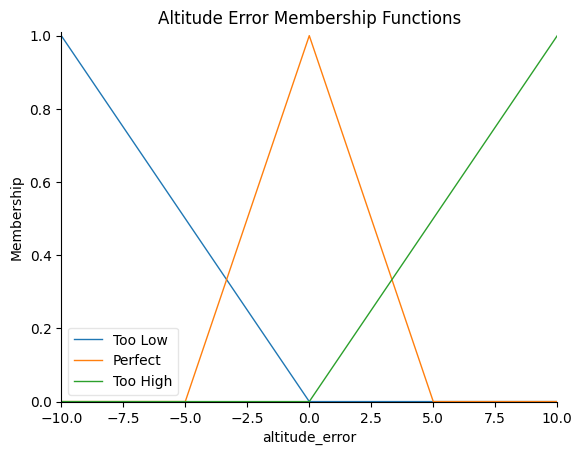

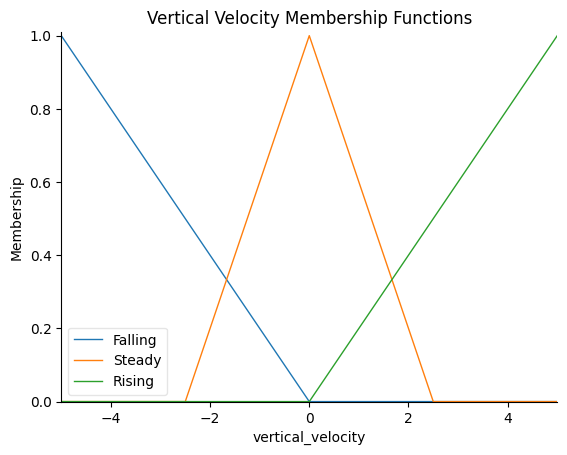

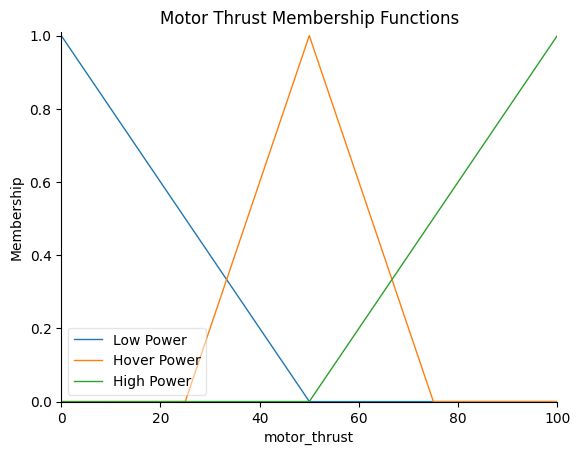

In [43]:
# ============================================================

# Altitude Error
altitude_error.view()
plt.title("Altitude Error Membership Functions")
plt.show()

# Vertical Velocity
vertical_velocity.view()
plt.title("Vertical Velocity Membership Functions")
plt.show()

# Motor Thrust
motor_thrust.view()
plt.title("Motor Thrust Membership Functions")
plt.show()


# ============================================================


7. FUZZY CONTROL RULES


In [44]:
#
# The PPT worked example explicitly evaluates these rules:
#
# R1: TL AND F -> High Power
# R2: TL AND S -> High Power
# R3: P  AND F -> High Power
# R4: P  AND S -> Hover Power
#
# The PPT's rule-base slide also gives physical-control
# rationales for additional situations. The rules below
# extend the controller so it can be tested across the
# complete input ranges while preserving the four worked
# example rules exactly.
# ============================================================

rule1 = ctrl.Rule(
    altitude_error['Too Low'] &
    vertical_velocity['Falling'],
    motor_thrust['High Power']
)

rule2 = ctrl.Rule(
    altitude_error['Too Low'] &
    vertical_velocity['Steady'],
    motor_thrust['High Power']
)

rule3 = ctrl.Rule(
    altitude_error['Perfect'] &
    vertical_velocity['Falling'],
    motor_thrust['High Power']
)

rule4 = ctrl.Rule(
    altitude_error['Perfect'] &
    vertical_velocity['Steady'],
    motor_thrust['Hover Power']
)

# Additional rules for a complete controller
rule5 = ctrl.Rule(
    altitude_error['Too Low'] &
    vertical_velocity['Rising'],
    motor_thrust['Hover Power']
)

rule6 = ctrl.Rule(
    altitude_error['Perfect'] &
    vertical_velocity['Rising'],
    motor_thrust['Hover Power']
)

rule7 = ctrl.Rule(
    altitude_error['Too High'] &
    vertical_velocity['Falling'],
    motor_thrust['Low Power']
)

rule8 = ctrl.Rule(
    altitude_error['Too High'] &
    vertical_velocity['Steady'],
    motor_thrust['Low Power']
)

rule9 = ctrl.Rule(
    altitude_error['Too High'] &
    vertical_velocity['Rising'],
    motor_thrust['Low Power']
)

print("Fuzzy control rules created successfully!")


# ============================================================


Fuzzy control rules created successfully!


8. CREATE FUZZY CONTROL SYSTEM


In [45]:
# ============================================================

system = ctrl.ControlSystem([
    rule1, rule2, rule3,
    rule4, rule5, rule6,
    rule7, rule8, rule9
])

print("Fuzzy Control System created successfully!")


# ============================================================


Fuzzy Control System created successfully!


9. CREATE SIMULATION OBJECT


Simulation object ready!

PPT WORKED EXAMPLE
Altitude Error      : -2.5 m
Vertical Velocity   : -1.25 m/s

Fuzzified values:
Too Low (TL)        : 0.25
Perfect (P)         : 0.50
Too High (TH)       : 0.00
Falling (F)         : 0.25
Steady (S)          : 0.50
Rising (R)          : 0.00

Rule firing strengths:
R1: TL AND F -> High Power   = 0.25
R2: TL AND S -> High Power   = 0.25
R3: P  AND F -> High Power   = 0.25
R4: P  AND S -> Hover Power  = 0.50

Aggregated output:
High Power firing strength  = 0.25
Hover Power firing strength = 0.50

------------------------------------------------------------
WEIGHTED AVERAGE DEFUZZIFICATION
------------------------------------------------------------
y* = (0.50 x 50 + 0.25 x 100) / (0.50 + 0.25)
Motor Thrust = 66.67 %
PPT expected result = 66.67 %
PPT result reproduced = 66.67 %

------------------------------------------------------------
SCIKIT-FUZZY MAMDANI OUTPUT
------------------------------------------------------------
Control-system de

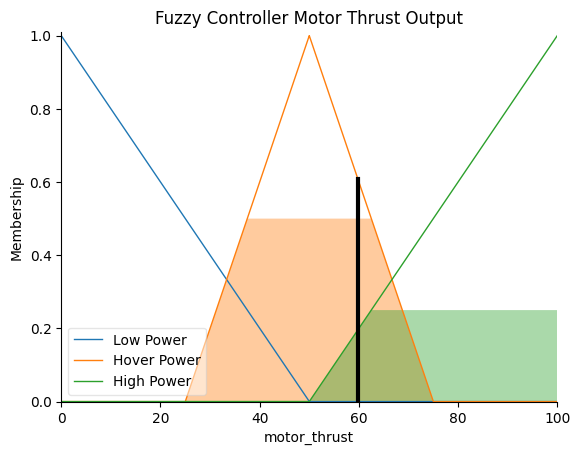

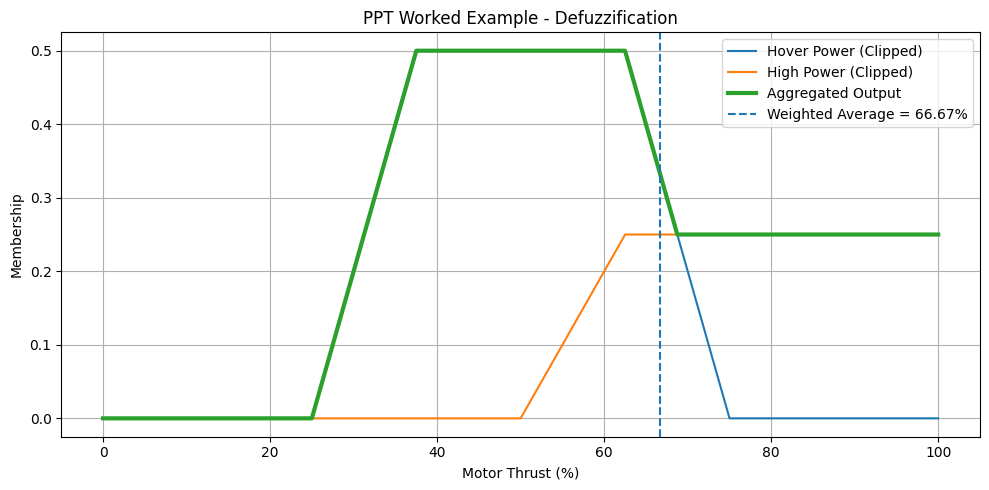


FUZZY CONTROLLER TEST CASES
Far below and falling          | Error =  -8.00 m | Velocity =  -3.00 m/s | Thrust =  81.43%
Slightly low and falling       | Error =  -2.50 m | Velocity =  -1.25 m/s | Thrust =  59.79%
At target and steady           | Error =   0.00 m | Velocity =   0.00 m/s | Thrust =  50.00%
Above target and rising        | Error =   5.00 m | Velocity =   2.00 m/s | Thrust =  20.42%

FUZZY UAV ALTITUDE CONTROLLER COMPLETED


In [46]:
# ============================================================

simulation = ctrl.ControlSystemSimulation(system)

print("Simulation object ready!")


# ============================================================
# 10. PPT WORKED EXAMPLE
#
# Sensor snapshot from PPT:
#   Altitude Error = -2.5 m
#   Vertical Velocity = -1.25 m/s
#
# PPT fuzzification:
#   TL = 0.25
#   P  = 0.50
#   TH = 0
#
#   F = 0.25
#   S = 0.50
#   R = 0
#
# Active rules:
#   R1 -> 0.25 High Power
#   R2 -> 0.25 High Power
#   R3 -> 0.25 High Power
#   R4 -> 0.50 Hover Power
#
# Aggregation:
#   High Power = max(0.25, 0.25, 0.25) = 0.25
#   Hover Power = 0.50
#
# Weighted Average:
#   y* = (0.50*50 + 0.25*100)/(0.50+0.25)
#      = 66.67 %
# ============================================================

simulation.input['altitude_error'] = -2.5
simulation.input['vertical_velocity'] = -1.25

simulation.compute()

print("\n" + "=" * 60)
print("PPT WORKED EXAMPLE")
print("=" * 60)

print("Altitude Error      :", -2.5, "m")
print("Vertical Velocity   :", -1.25, "m/s")

print("\nFuzzified values:")
print("Too Low (TL)        : 0.25")
print("Perfect (P)         : 0.50")
print("Too High (TH)       : 0.00")
print("Falling (F)         : 0.25")
print("Steady (S)          : 0.50")
print("Rising (R)          : 0.00")

print("\nRule firing strengths:")
print("R1: TL AND F -> High Power   = 0.25")
print("R2: TL AND S -> High Power   = 0.25")
print("R3: P  AND F -> High Power   = 0.25")
print("R4: P  AND S -> Hover Power  = 0.50")

print("\nAggregated output:")
print("High Power firing strength  = 0.25")
print("Hover Power firing strength = 0.50")


# ============================================================
# 11. WEIGHTED AVERAGE DEFUZZIFICATION
#
# This is the defuzzification method explicitly used in
# the PPT's worked example.
# ============================================================

hover_strength = 0.50
high_strength = 0.25

hover_peak = 50
high_peak = 100

weighted_average = (
    hover_strength * hover_peak +
    high_strength * high_peak
) / (
    hover_strength + high_strength
)

print("\n" + "-" * 60)
print("WEIGHTED AVERAGE DEFUZZIFICATION")
print("-" * 60)

print(
    "y* = (0.50 x 50 + 0.25 x 100) / (0.50 + 0.25)"
)

print("Motor Thrust =", round(weighted_average, 2), "%")

print("PPT expected result = 66.67 %")
print("PPT result reproduced =", round(weighted_average, 2), "%")


# ============================================================
# 12. SCIKIT-FUZZY MAMDANI OUTPUT
#
# ControlSystemSimulation uses the fuzzy output membership
# functions and produces a crisp result. This is useful for
# showing the actual fuzzy-controller implementation.
# ============================================================

print("\n" + "-" * 60)
print("SCIKIT-FUZZY MAMDANI OUTPUT")
print("-" * 60)

print(
    "Control-system defuzzified thrust =",
    round(simulation.output['motor_thrust'], 2),
    "%"
)


# ============================================================
# 13. DISPLAY OUTPUT GRAPH
# ============================================================

motor_thrust.view(sim=simulation)
plt.title("Fuzzy Controller Motor Thrust Output")
plt.show()


# ============================================================
# 14. PLOT THE PPT WORKED-EXAMPLE AGGREGATED OUTPUT
# ============================================================

hover_clipped = np.minimum(
    hover_strength,
    motor_thrust['Hover Power'].mf
)

high_clipped = np.minimum(
    high_strength,
    motor_thrust['High Power'].mf
)

aggregated_output = np.maximum(
    hover_clipped,
    high_clipped
)

plt.figure(figsize=(10, 5))

plt.plot(
    motor_thrust.universe,
    hover_clipped,
    label="Hover Power (Clipped)"
)

plt.plot(
    motor_thrust.universe,
    high_clipped,
    label="High Power (Clipped)"
)

plt.plot(
    motor_thrust.universe,
    aggregated_output,
    linewidth=3,
    label="Aggregated Output"
)

plt.axvline(
    weighted_average,
    linestyle="--",
    label=f"Weighted Average = {weighted_average:.2f}%"
)

plt.xlabel("Motor Thrust (%)")
plt.ylabel("Membership")
plt.title("PPT Worked Example - Defuzzification")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 15. TEST DIFFERENT UAV CONDITIONS
# ============================================================

def run_test(error, velocity, scenario):
    """
    Run the fuzzy controller for a given UAV condition.
    """

    test_simulation = ctrl.ControlSystemSimulation(system)

    test_simulation.input['altitude_error'] = error
    test_simulation.input['vertical_velocity'] = velocity

    test_simulation.compute()

    result = test_simulation.output['motor_thrust']

    print(
        f"{scenario:<30} | "
        f"Error = {error:>6.2f} m | "
        f"Velocity = {velocity:>6.2f} m/s | "
        f"Thrust = {result:>6.2f}%"
    )

    return result


print("\n" + "=" * 80)
print("FUZZY CONTROLLER TEST CASES")
print("=" * 80)

run_test(
    -8.0, -3.0,
    "Far below and falling"
)

run_test(
    -2.5, -1.25,
    "Slightly low and falling"
)

run_test(
    0.0, 0.0,
    "At target and steady"
)

run_test(
    5.0, 2.0,
    "Above target and rising"
)


# ============================================================
# 16. OPTIONAL LIVE SENSOR INPUT
# ============================================================
#
# Uncomment this section if you want to enter sensor values
# manually from the VS Code terminal.
#
# error = float(input("Enter altitude error (-10 to +10 m): "))
# velocity = float(input("Enter vertical velocity (-5 to +5 m/s): "))
#
# error = np.clip(error, -10, 10)
# velocity = np.clip(velocity, -5, 5)
#
# live_simulation = ctrl.ControlSystemSimulation(system)
# live_simulation.input['altitude_error'] = error
# live_simulation.input['vertical_velocity'] = velocity
# live_simulation.compute()
#
# print(
#     "Recommended Motor Thrust:",
#     round(live_simulation.output['motor_thrust'], 2),
#     "%"
# )


# ============================================================
# PROJECT END
# ============================================================

print("\n" + "=" * 60)
print("FUZZY UAV ALTITUDE CONTROLLER COMPLETED")
print("=" * 60)


# PHASE 4 – TESTING

This phase tests the UAV Fuzzy Altitude Controller using **10 different combinations** of:

- Altitude Error (m)
- Vertical Velocity (m/s)
- Motor Thrust (%)

The test cases include favourable, moderate, and critical UAV altitude conditions.


In [47]:
# Step 1: Define 10 different test cases

test_cases = [
    {"altitude_error": -8,  "vertical_velocity": -3,   "scenario": "Far below and falling"},
    {"altitude_error": -5,  "vertical_velocity": -1,   "scenario": "Below target and falling"},
    {"altitude_error": -2.5,"vertical_velocity": -1.25,"scenario": "Slightly low and falling"},
    {"altitude_error": 0,   "vertical_velocity": 0,    "scenario": "At target and steady"},
    {"altitude_error": 2,   "vertical_velocity": -2,   "scenario": "Above target but falling"},
    {"altitude_error": 5,   "vertical_velocity": 0,    "scenario": "Above target and steady"},
    {"altitude_error": 8,   "vertical_velocity": 2,    "scenario": "Far above and rising"},
    {"altitude_error": -8,  "vertical_velocity": 0,    "scenario": "Far below and steady"},
    {"altitude_error": -2,  "vertical_velocity": 2,    "scenario": "Below target and rising"},
    {"altitude_error": 2,   "vertical_velocity": 2,    "scenario": "Above target and rising"}
]

print("Number of test cases:", len(test_cases))


Number of test cases: 10


## Step 2: Run the Fuzzy Controller on the 10 Test Cases

Each test case is passed through the same Mamdani fuzzy inference system defined earlier.
The calculated motor thrust is stored in a table for easy comparison.


In [48]:
# Step 2: Run all 10 test cases

test_results = []

for i, case in enumerate(test_cases, 1):
    test_simulation = ctrl.ControlSystemSimulation(system)

    test_simulation.input['altitude_error'] = case['altitude_error']
    test_simulation.input['vertical_velocity'] = case['vertical_velocity']

    test_simulation.compute()

    thrust = test_simulation.output['motor_thrust']

    test_results.append({
        "Test Case": i,
        "Altitude Error (m)": case['altitude_error'],
        "Vertical Velocity (m/s)": case['vertical_velocity'],
        "Motor Thrust (%)": round(thrust, 2),
        "Scenario": case['scenario']
    })

test_results_df = pd.DataFrame(test_results)
display(test_results_df)


,Test Case,Altitude Error (m),Vertical Velocity (m/s),Motor Thrust (%),Scenario
0,1,-8.0,-3.00,81.43,Far below and falling
1,2,-5.0,-1.00,80.56,Below target and falling
2,3,-2.5,-1.25,59.79,Slightly low and falling
3,4,0.0,0.00,50.00,At target and steady
4,5,2.0,-2.00,58.40,Above target but falling
5,6,5.0,0.00,19.44,Above target and steady
6,7,8.0,2.00,20.42,Far above and rising
7,8,-8.0,0.00,82.78,Far below and steady
8,9,-2.0,2.00,59.26,Below target and rising
9,10,2.0,2.00,40.74,Above target and rising


## Step 3: Highest and Lowest Motor Thrust

The highest and lowest thrust outputs are identified from the 10 test cases.


In [53]:
# Find highest and lowest thrust outputs

highest = test_results_df.loc[test_results_df["Motor Thrust (%)"].idxmax()]
lowest = test_results_df.loc[test_results_df["Motor Thrust (%)"].idxmin()]

print("Highest Motor Thrust:")
display(highest.to_frame().T)

print("\nLowest Motor Thrust:")
display(lowest.to_frame().T)


Highest Motor Thrust:


,Test Case,Altitude Error (m),Vertical Velocity (m/s),Motor Thrust (%),Scenario
7,8,-8.0,0.0,82.78,Far below and steady



Lowest Motor Thrust:


,Test Case,Altitude Error (m),Vertical Velocity (m/s),Motor Thrust (%),Scenario
5,6,5.0,0.0,19.44,Above target and steady


## Step 4: Three Different Input and Output Combinations

The following examples show how different UAV conditions produce different motor-thrust outputs.


In [50]:
# Display three representative combinations

three_examples = test_results_df.iloc[[0, 3, 6]]
display(three_examples)


,Test Case,Altitude Error (m),Vertical Velocity (m/s),Motor Thrust (%),Scenario
0,1,-8.0,-3.0,81.43,Far below and falling
3,4,0.0,0.0,50.00,At target and steady
6,7,8.0,2.0,20.42,Far above and rising


## Step 5: Visualize the Test Results

The graph below compares the motor-thrust output for all 10 test cases.


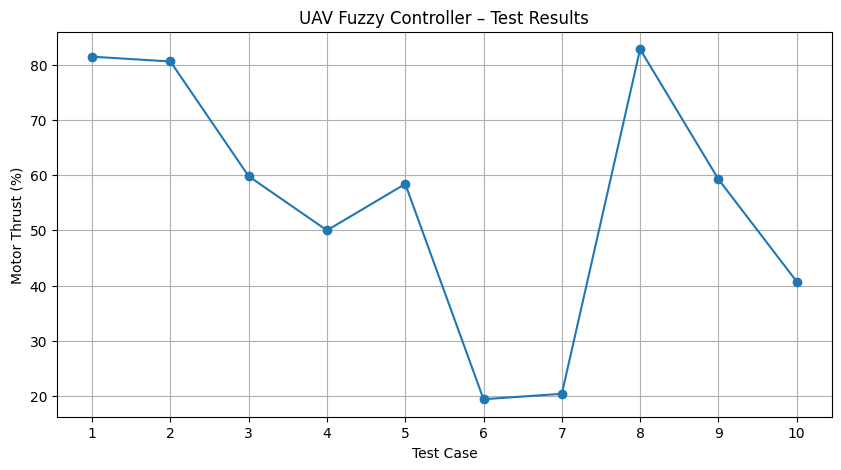

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(
    test_results_df["Test Case"],
    test_results_df["Motor Thrust (%)"],
    marker='o'
)
plt.xlabel("Test Case")
plt.ylabel("Motor Thrust (%)")
plt.title("UAV Fuzzy Controller – Test Results")
plt.xticks(test_results_df["Test Case"])
plt.grid(True)
plt.show()


# PHASE 5 – ANALYSIS

## Controller Behaviour

The fuzzy controller combines **Altitude Error** and **Vertical Velocity** to determine the required Motor Thrust.

- When the UAV is below the desired altitude, the controller generally increases thrust.
- When the UAV is above the desired altitude, the controller generally reduces thrust.
- When the altitude is near the target and vertical velocity is near zero, the controller operates around the hover-thrust region.
- The vertical velocity input helps the controller consider whether the UAV is falling or rising, instead of using altitude error alone.
- Because fuzzy logic uses gradual membership functions, the controller provides a smooth rule-based response instead of a simple ON/OFF decision.


## Strengths of the Controller

- Uses two important UAV parameters simultaneously.
- Fuzzy rules are easy to understand and modify.
- Provides gradual control instead of only ON/OFF control.
- Does not require a complete mathematical model for the rule-based decision process.
- Simple structure makes it suitable for demonstration and further development.
- The controller can be tested with many different combinations of altitude error and velocity.


## Weaknesses of the Controller

- The performance depends strongly on the selected membership functions.
- The current system uses a limited 3 × 3 rule structure.
- The membership-function ranges are manually selected.
- Real UAV effects such as wind, drag, battery condition, payload, and sensor noise are not included.
- The present testing uses selected input combinations rather than long-duration real-flight data.


## Scope for Improvement

The controller can be improved by:

1. Adding more membership functions for finer control.
2. Refining the fuzzy rules using real UAV flight data.
3. Adding sensor filtering to reduce noise.
4. Including disturbances such as wind and payload changes in simulation.
5. Developing a more detailed UAV dynamic model.
6. Using adaptive or neuro-fuzzy methods to tune membership functions automatically.
7. Implementing and testing the controller on real UAV hardware after proper simulation and safety validation.


# PHASE 6 – USER INTERFACE

A simple interactive user interface is created using **IPyWidgets**.

The user can change:
- Altitude Error
- Vertical Velocity

The fuzzy controller then displays the calculated Motor Thrust and a simple controller status.


In [52]:
# Step 6: Create the interactive user interface

import ipywidgets as widgets
from IPython.display import display, clear_output

altitude_input = widgets.FloatSlider(
    value=0,
    min=-10,
    max=10,
    step=0.1,
    description='Altitude Error:',
    continuous_update=False,
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='500px')
)

velocity_input = widgets.FloatSlider(
    value=0,
    min=-5,
    max=5,
    step=0.1,
    description='Vertical Velocity:',
    continuous_update=False,
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='500px')
)

calculate_button = widgets.Button(
    description='Calculate Motor Thrust',
    button_style='primary'
)

output = widgets.Output()

def calculate_thrust(b):
    with output:
        clear_output()

        ui_simulation = ctrl.ControlSystemSimulation(system)
        ui_simulation.input['altitude_error'] = altitude_input.value
        ui_simulation.input['vertical_velocity'] = velocity_input.value
        ui_simulation.compute()

        thrust = ui_simulation.output['motor_thrust']

        if thrust >= 75:
            status = "HIGH POWER"
        elif thrust >= 40:
            status = "HOVER / MEDIUM POWER"
        else:
            status = "LOW POWER"

        print("UAV FUZZY ALTITUDE CONTROLLER")
        print("--------------------------------")
        print(f"Altitude Error   : {altitude_input.value:.2f} m")
        print(f"Vertical Velocity: {velocity_input.value:.2f} m/s")
        print(f"Motor Thrust     : {thrust:.2f} %")
        print(f"Controller Status: {status}")

calculate_button.on_click(calculate_thrust)

display(
    widgets.VBox([
        widgets.HTML("<h2>UAV Fuzzy Altitude Controller</h2>"),
        altitude_input,
        velocity_input,
        calculate_button,
        output
    ])
)


## Step 7: Test the User Interface

Change the two sliders and click **Calculate Motor Thrust**.

Suggested demonstrations:

| Altitude Error | Vertical Velocity | Expected condition |
|---:|---:|---|
| -8 | -3 | UAV far below and falling |
| 0 | 0 | UAV at target and steady |
| 8 | 2 | UAV far above and rising |

Take a screenshot of the UI after calculating a result.


# PHASE 6 – FINAL UI DEMONSTRATION

The completed interface allows the user to provide the two fuzzy-controller inputs and immediately observe the motor-thrust output.

This completes the Testing, Analysis, and UI requirements for the UAV Fuzzy Altitude Controller.
